<a href="https://colab.research.google.com/github/debrah9504/COU07506-labs/blob/main/COU07506_Week01_%3C240242496248%3E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 Digital Signal Processing — Week 01: Lab 0 Setting Up the DSP Laboratory
Name: DEBORA DESDEUS SWAI
Registration No.: 240242496248
Class: BEng24COE  
Date: 24/11/2026

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

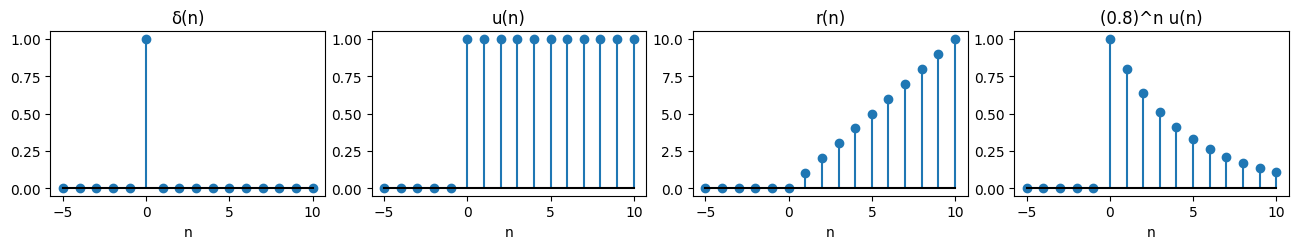

In [ ]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step  = (n >= 0).astype(float)   # unit step
ramp  = n * step                 # unit ramp
expo  = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

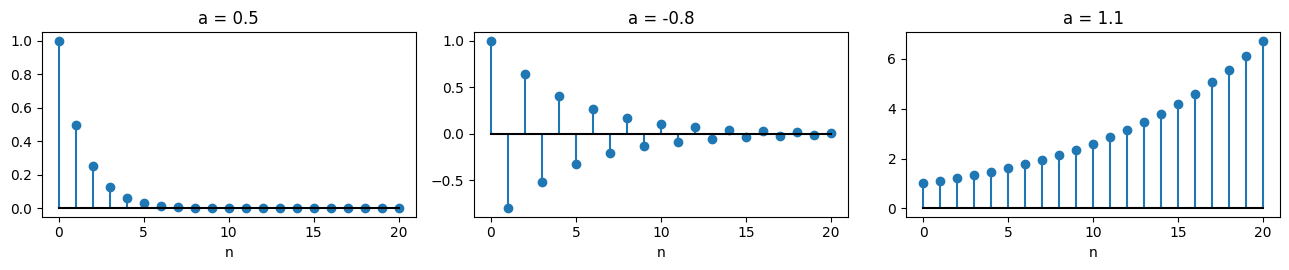

In [ ]:
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

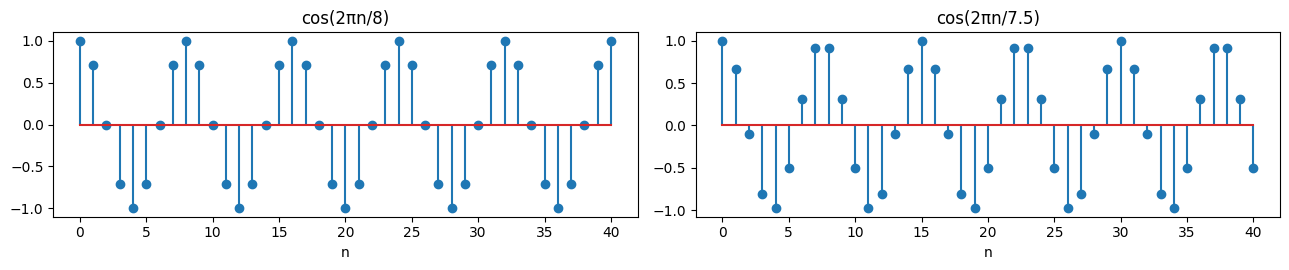

In [ ]:
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
axes[0].stem(n, np.cos(2*np.pi*n/8));   axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, np.cos(2*np.pi*n/7.5)); axes[1].set_title("cos(2πn/7.5)")
for ax in axes: ax.set_xlabel("n")
plt.tight_layout(); plt.show()

In [3]:
!ls /content

 sample_data  'Voice 010.m4a'


In [5]:
!ffmpeg -y -i "/content/Voice 010.m4a" -ar 16000 -ac 1 /content/my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [6]:
import os
print(os.path.exists("/content/my_voice.wav"))

True


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

fs = 16000 Hz, duration = 4.78 s, samples = 76533


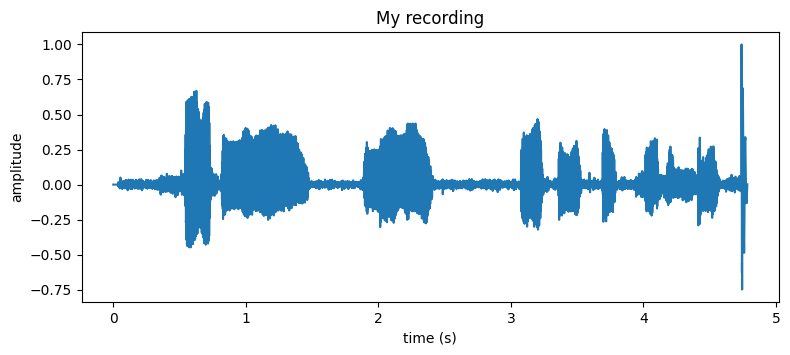

In [9]:
import os
fname = "/content/my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:              # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))   # normalise to [-1, 1]
else:                           # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

## AI-use statement
AI tools used: Claude
Used for: guiding me through the Colab setup, converting my m4a recording to WAV with ffmpeg, and fixing errors (file name and NameError)
How I verified the output: I compared my plots with the expected results in the lab manual, and I checked that the printed sampling rate, duration and number of samples matched my own recording
I confirm that I understand and can explain all submitted code.